# Summative Lab - Analytics Firm Clients: Customer Reviews Analysis

Three parts on one dataset of Amazon customer reviews (`amazon_reviews_lab.csv`):
1. **NLP** - clean review text, find frequent words and bigrams
2. **Time Series** - review volume and ratings over time (stationarity, ARIMA forecast)
3. **Neural Networks** - predict the star rating from review text

# Part 1 : NLP

In [2]:
# Import necessary libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re
import string
from collections import Counter


# For text preprocessing
import nltk
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer, WordNetLemmatizer
from nltk.util import ngrams


# Download necessary NLTK data
nltk.download('punkt')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('averaged_perceptron_tagger')
nltk.download('punkt_tab')
nltk.download('averaged_perceptron_tagger_eng')

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\user\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\user\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\user\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     C:\Users\user\AppData\Roaming\nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\user\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger_eng to
[nltk_data]     C:\Users\user\AppData\Roaming\nltk_data...
[nltk_data]   Package averaged_perceptr

True

In [3]:
# load and explore dataset
df = pd.read_csv('amazon_reviews_lab.csv')
print(df.shape)
df.head()

(997, 9)


,product_id,rating,review_text,review_summary,review_time_raw,unix_review_time,timestamp,sentiment_label,review_length_words
0,6301977173,2,This film is definitely not for anyone who is ...,The best of Mark Twain's work - left out!,"05 12, 2000",9.580896e+08,2000-05-12,negative,302
1,6301977173,5,This movie was playing at Radio City Music Hal...,The best Tom Sawyer i ever saw.,"08 26, 2002",1.030320e+09,2002-08-26,positive,168
2,6301977173,1,I would love to buy this movie as I have been ...,Why no Widescreen?,"08 6, 2005",1.123286e+09,2005-08-06,negative,60
3,6301977173,1,The advertisment for this DVD on Amazon was in...,False advertising on this DVD,"09 11, 2005",1.126397e+09,2005-09-11,negative,104
4,9575871979,5,I bought some of these to try with a light usi...,Work GREAT!!,"10 15, 2007",1.192406e+09,2007-10-15,positive,60


In [6]:
# columns
df.columns

Index(['product_id', 'rating', 'review_text', 'review_summary',
       'review_time_raw', 'unix_review_time', 'timestamp', 'sentiment_label',
       'review_length_words'],
      dtype='object')

In [5]:
df['rating'].value_counts().sort_index()

rating
1     87
2     48
3     94
4    188
5    580
Name: count, dtype: int64

In [7]:
# data types
df.dtypes

product_id              object
rating                   int64
review_text             object
review_summary          object
review_time_raw         object
unix_review_time       float64
timestamp               object
sentiment_label         object
review_length_words      int64
dtype: object

In [8]:
display(df[['rating', 'review_text', 'sentiment_label']].head(5))

,rating,review_text,sentiment_label
0,2,This film is definitely not for anyone who is ...,negative
1,5,This movie was playing at Radio City Music Hal...,positive
2,1,I would love to buy this movie as I have been ...,negative
3,1,The advertisment for this DVD on Amazon was in...,negative
4,5,I bought some of these to try with a light usi...,positive


In [9]:
# missing values
df.isnull().sum()

product_id             0
rating                 0
review_text            0
review_summary         0
review_time_raw        0
unix_review_time       0
timestamp              0
sentiment_label        0
review_length_words    0
dtype: int64

In [10]:
# duplicates
df.duplicated().sum()

np.int64(0)

In [11]:
# summary statistics
df.describe()

,rating,unix_review_time,review_length_words
count,997.000000,9.970000e+02,997.000000
mean,4.129388,1.344766e+09,146.374122
std,1.280181,4.411420e+07,216.126770
min,1.000000,9.580896e+08,5.000000
25%,4.000000,1.311898e+09,32.000000
50%,5.000000,1.356048e+09,67.000000
75%,5.000000,1.379462e+09,165.000000
max,5.000000,1.405555e+09,2079.000000


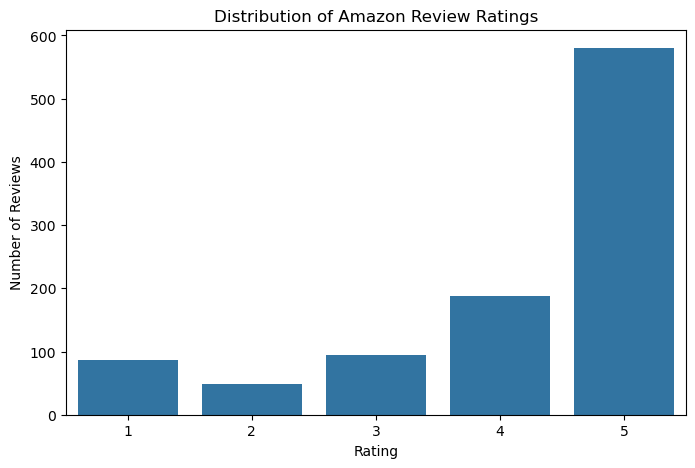

In [12]:
# Distribution of customer ratings
plt.figure(figsize=(8, 5))

sns.countplot(data=df, x='rating')

plt.title('Distribution of Amazon Review Ratings')
plt.xlabel('Rating')
plt.ylabel('Number of Reviews')
plt.show()


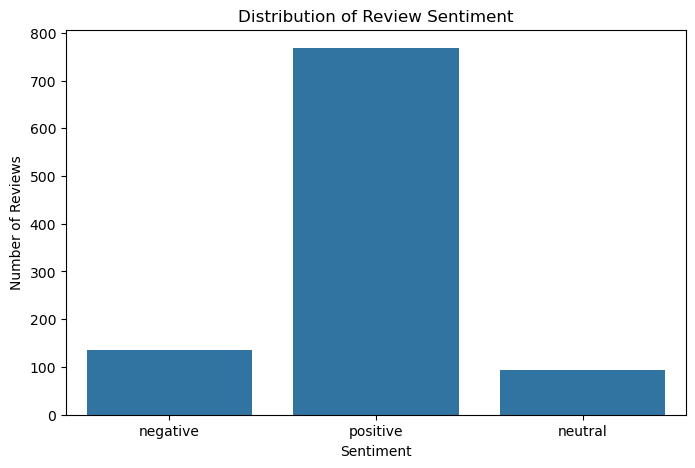

In [13]:
# sentiment distribution
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='sentiment_label')

plt.title('Distribution of Review Sentiment')
plt.xlabel('Sentiment')
plt.ylabel('Number of Reviews')
plt.show()

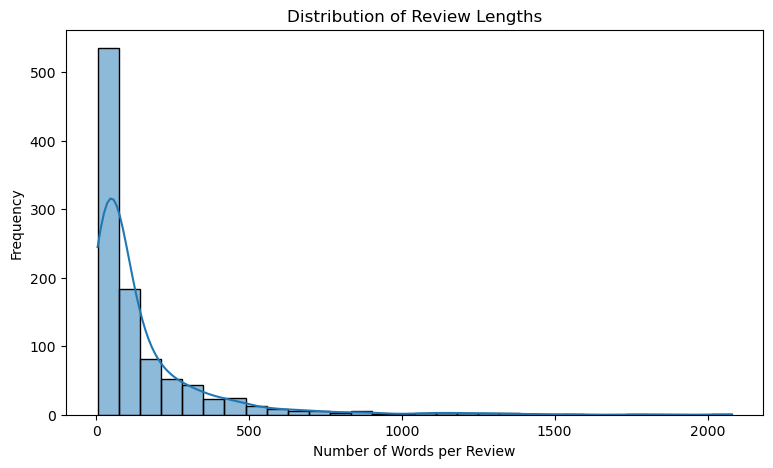

In [14]:
# review length distribution
plt.figure(figsize=(9, 5))

sns.histplot(data=df, x='review_length_words', bins=30, kde=True)

plt.title('Distribution of Review Lengths')
plt.xlabel('Number of Words per Review')
plt.ylabel('Frequency')
plt.show()

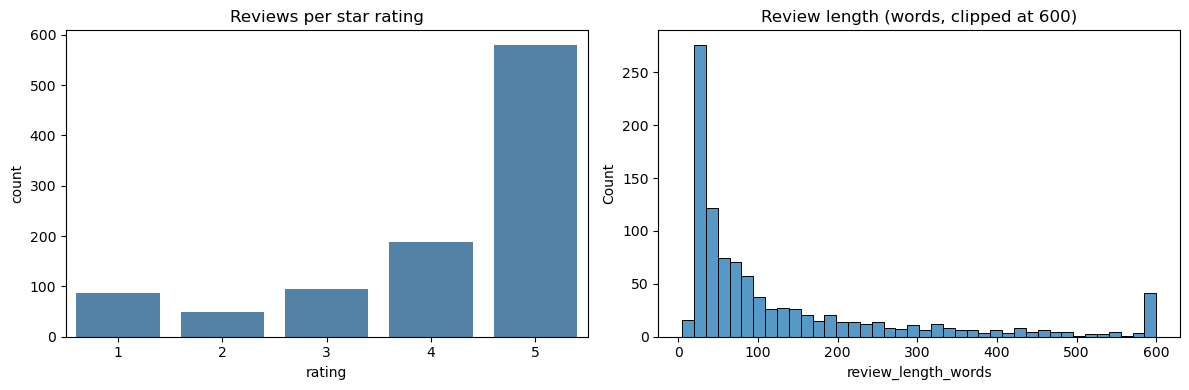

count     997.000000
mean      146.374122
std       216.126770
min         5.000000
25%        32.000000
50%        67.000000
75%       165.000000
max      2079.000000
Name: review_length_words, dtype: float64
Empty reviews: 0


In [16]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(x='rating', data=df, ax=ax[0], color='steelblue'); ax[0].set_title('Reviews per star rating')
sns.histplot(df['review_length_words'].clip(upper=600), bins=40, ax=ax[1]); ax[1].set_title('Review length (words, clipped at 600)')
plt.tight_layout(); plt.show()
print(df['review_length_words'].describe())
print("Empty reviews:", (df['review_text'].str.strip() == '').sum())

In [ ]:
# Preprocessing